# Titanic Dataset Analysis

This project focuses on exploring and analyzing the Titanic dataset using Python and data analysis libraries. The goal is to understand the dataset, identify patterns and relationships between different passenger attributes, and gain insights through data exploration and visualization.

**Tools & Libraries:** Python, NumPy, Pandas, Matplotlib, Seaborn

In [106]:
import pandas as pd
from pandas import Series, DataFrame

In [108]:
titanic_df = pd.read_csv('train.csv')
titanic_df.head()
# parch:parents or children
# embarks: letters stands for towns or cities (Q,S,C)

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [110]:
titanic_df.info()
# we miss lots of info on cabin

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   name      891 non-null    object 
 3   sex       891 non-null    object 
 4   age       714 non-null    float64
 5   sibsp     891 non-null    int64  
 6   parch     891 non-null    int64  
 7   ticket    891 non-null    object 
 8   fare      891 non-null    float64
 9   cabin     204 non-null    object 
 10  embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 76.7+ KB


**Who were the passengers on the titanic?**
-

In [113]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

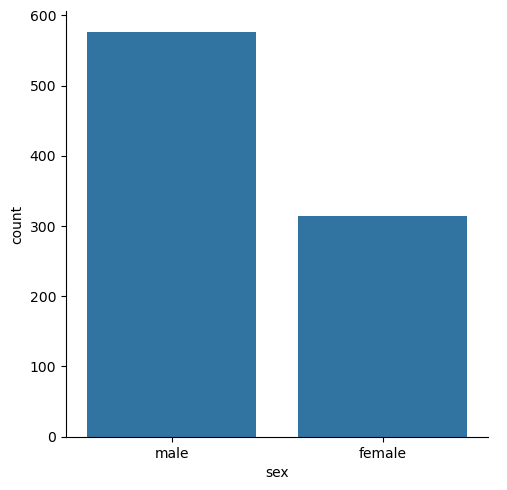

In [115]:
sns.catplot(data=titanic_df,x='sex',kind='count')

**separate genders by classes**

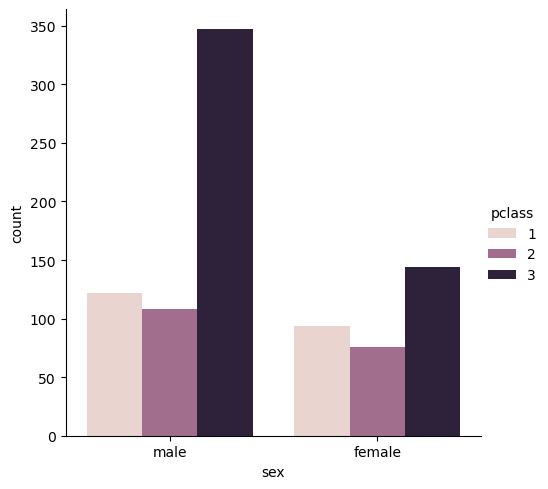

In [117]:
sns.catplot(data=titanic_df,x='sex',hue='pclass',kind='count')
# most of mans are in third class

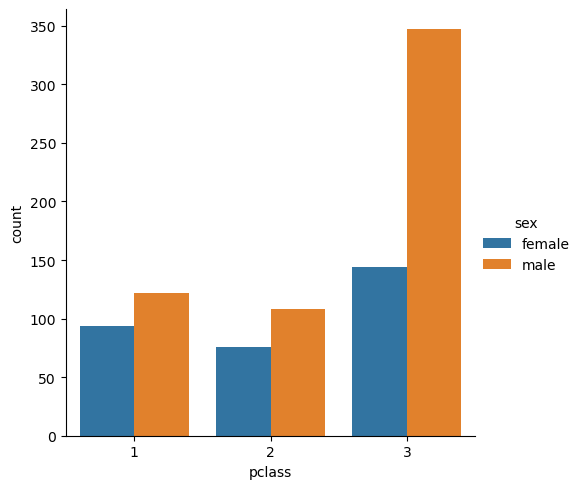

In [119]:
sns.catplot(data=titanic_df,x='pclass',kind='count',hue='sex')

**male,female,children**

**`apply()`**: Applies a function to each value, row, or column of a DataFrame or Series.

**Use:** To perform a custom operation or transformation on data.


In [122]:
def male_female_child(passenger):
    age,sex = passenger

    if age < 16:
        return 'child'
    else:
        return sex

In [125]:
titanic_df['person'] = titanic_df[['age','sex']].apply(male_female_child,axis=1)

In [127]:
# titanic_df[['age','sex']]

In [129]:
titanic_df[0:10]

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male
5,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,male
6,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,male
7,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,child
8,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,female
9,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,child


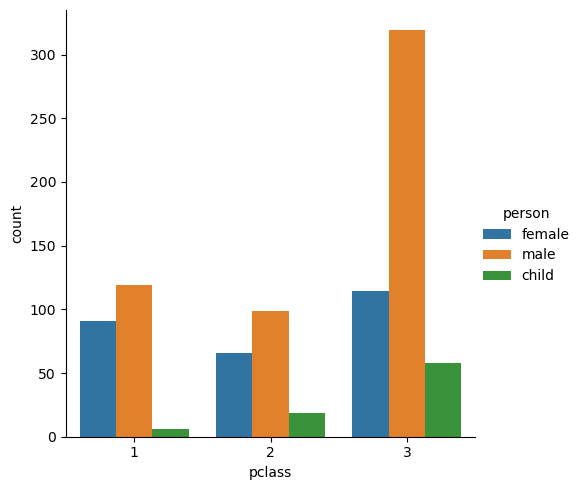

In [131]:
sns.catplot(data=titanic_df,x='pclass',hue='person',kind='count')  

<Axes: >

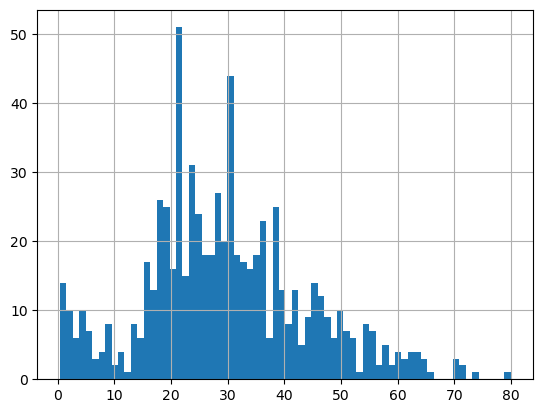

In [132]:
titanic_df['age'].hist(bins=70)

In [134]:
titanic_df['age'].mean()

29.69911764705882

In [137]:
titanic_df['person'].value_counts()

person
male      537
female    271
child      83
Name: count, dtype: int64

p2
-

**kde plots for analyzing ages and genders**

**FacetGrid**
-
**FacetGrid:** A Seaborn tool for creating multiple plots on one figure based on different groups or categories in a dataset.

**Use:** To compare distributions or relationships between different groups.

**`map()`**: Applies a function to each item in an iterable and returns the results.


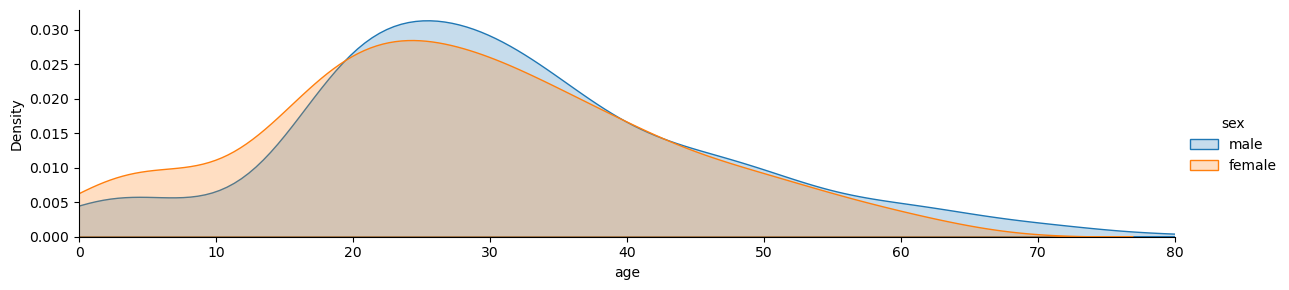

In [140]:
# aspect:نسبت ابعاد 

fig = sns.FacetGrid(titanic_df,hue='sex',aspect=4)
# برای هر گروهی که در فیست گریدداریم، تابع sns.kdeplot را روی ستون age اجرا کن.
fig.map(sns.kdeplot,'age',fill=True)

oldest = titanic_df['age'].max()

fig.set(xlim=(0,oldest))

fig.add_legend()

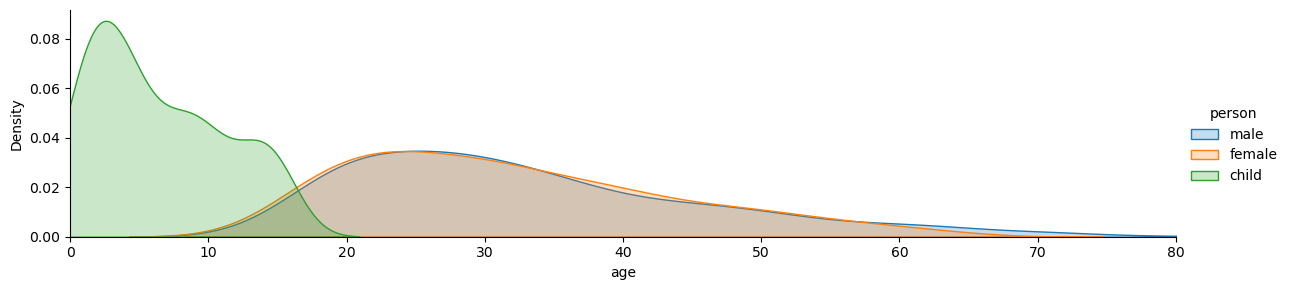

In [141]:
fig = sns.FacetGrid(titanic_df,hue='person',aspect=4)
fig.map(sns.kdeplot,'age',fill=True)

oldest = titanic_df['age'].max()

fig.set(xlim=(0,oldest))

fig.add_legend()

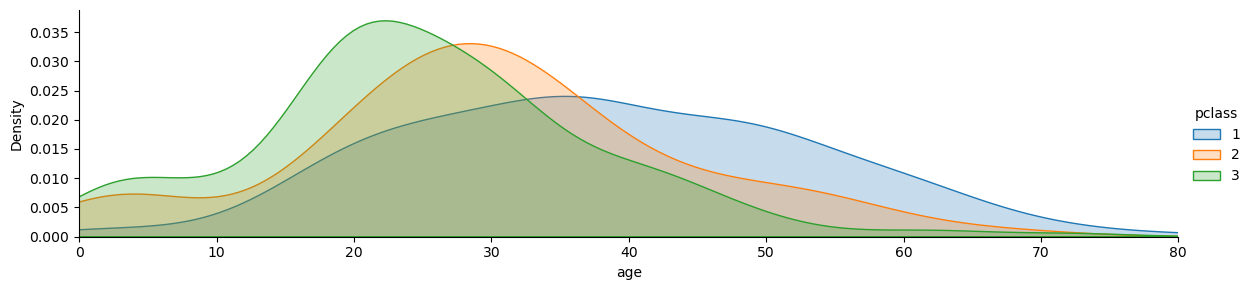

In [142]:
# ages range by class
fig = sns.FacetGrid(titanic_df,hue='pclass',aspect=4)
fig.map(sns.kdeplot,'age',fill=True)

oldest = titanic_df['age'].max()

fig.set(xlim=(0,oldest))

fig.add_legend()

**2-what deck were passengers on and how does that related to their class?**
-

In [147]:
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male


In [149]:
# getride of null values
deck = titanic_df['cabin'].dropna()

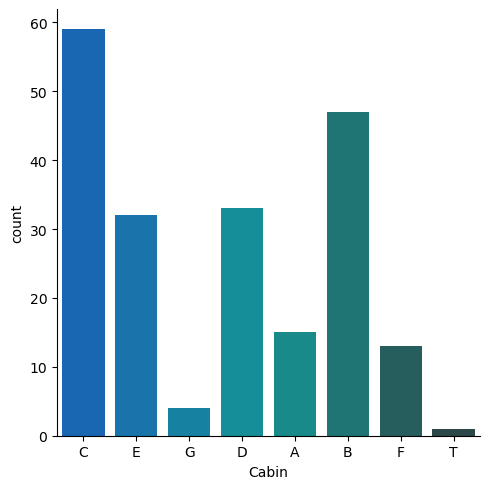

In [151]:
# we only need ABCDEFG
# hue یعنی داده‌ها را بر اساس یک ستون دسته‌بندی کن و برای هر دسته رنگ متفاوت استفاده کن.
levels = []

for level in deck:
    levels.append(level[0])

cabin_df = DataFrame(levels)
cabin_df.columns = ['Cabin']
# plot dataframe
# all cabins and count of every people in them
sns.catplot(data=cabin_df,x='Cabin',kind='count',hue='Cabin',palette='winter_d')

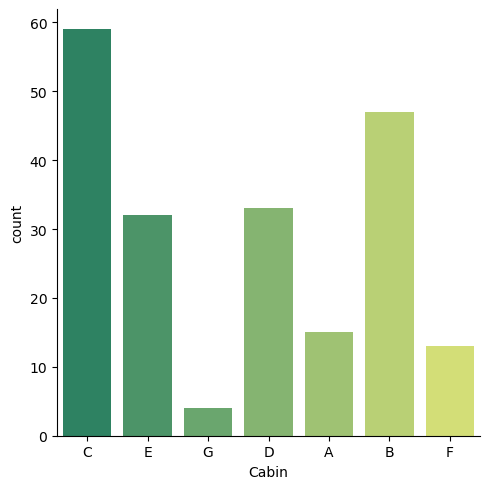

In [152]:
# T cabin doesn't make sense so we drop it out
cabin_df = cabin_df[cabin_df.Cabin != 'T']
sns.catplot(data=cabin_df,x='Cabin',hue='Cabin',palette='summer',kind='count')

In [155]:
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male


**3-where is the passengers come from?**
--

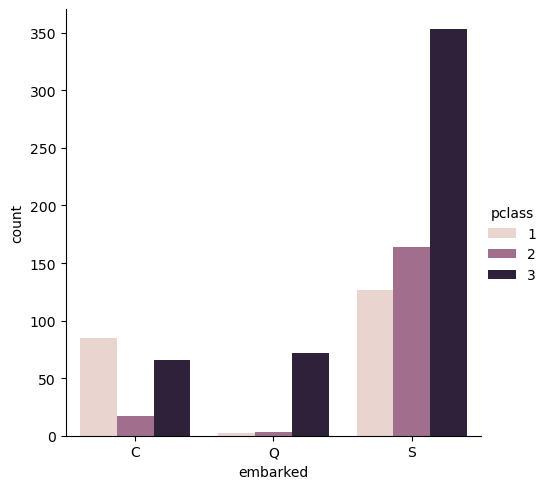

In [158]:
# hue='pcalss':  we see all the citites embarked and who from which class came on which cities
sns.catplot(data=titanic_df,x='embarked',hue='pclass',kind='count',order=['C','Q','S'])

# most of people was boarded was from Q city was from third class.economic of that city may be was bad

**4-Who was alone and who was with family?**
--

In [161]:
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male


In [163]:
# me
def fam_alone(passenger):
    
    sib,par = passenger
    if sib==0 and par==0:
        return 'alone'
    else:    
        return 'with Family'

In [165]:
# me
titanic_df['family_alone'] = titanic_df[['sibsp','parch']].apply(fam_alone,axis=1)

In [167]:
# me
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person,family_alone
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male,with Family
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female,with Family
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female,alone
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female,with Family
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male,alone


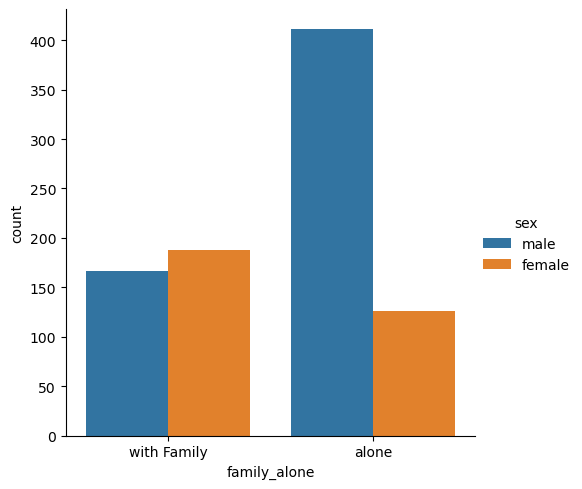

In [169]:
# me
sns.catplot(data=titanic_df,kind='count',x='family_alone',hue='sex')

In [170]:
# jose
titanic_df['alone'] = titanic_df.sibsp + titanic_df.parch

In [173]:
titanic_df['alone'].head()

0    1
1    1
2    0
3    1
4    0
Name: alone, dtype: int64

In [175]:
titanic_df['alone'] = titanic_df['alone'].astype('object')

titanic_df.loc[titanic_df['alone'] > 0, 'alone'] = 'With Family'

titanic_df.loc[titanic_df['alone'] == 0, 'alone'] = 'Alone'

In [177]:
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person,family_alone,alone
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male,with Family,With Family
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female,with Family,With Family
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female,alone,Alone
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female,with Family,With Family
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male,alone,Alone


C:\Users\ALFA\AppData\Local\Temp\ipykernel_2900\3855518943.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(data=titanic_df,palette='Blues',x='alone',kind='count')


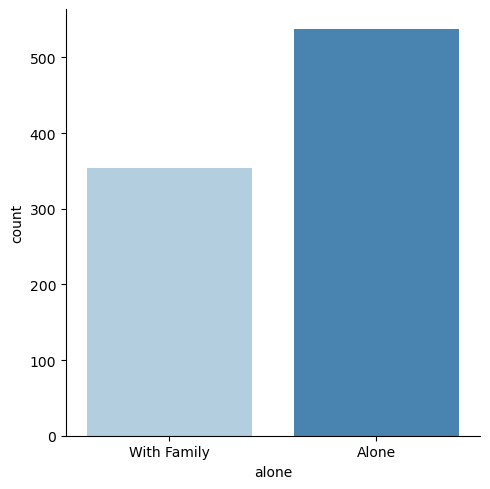

In [179]:
sns.catplot(data=titanic_df,palette='Blues',x='alone',kind='count')

**-5 What factors help someone survive the sinking or crash of titanic?**
--

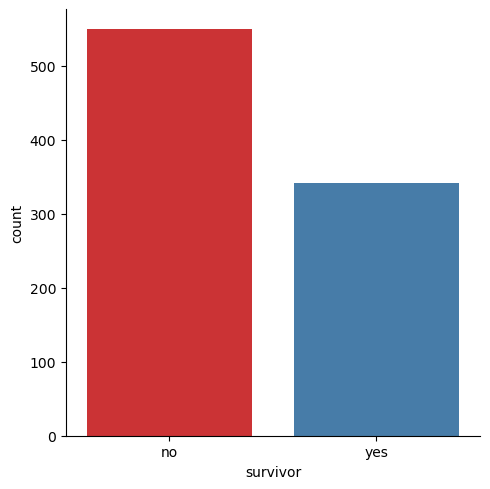

In [182]:
titanic_df['survivor'] = titanic_df.survived.map({0:'no',1:'yes'})
sns.catplot(data=titanic_df,x='survivor',palette='Set1',kind='count',hue='survivor')

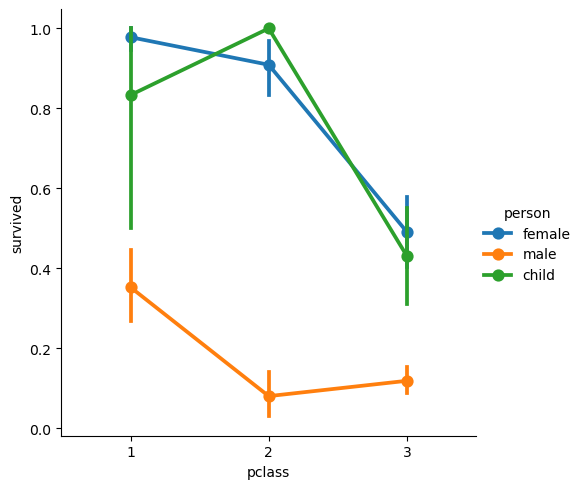

In [184]:
sns.catplot(data=titanic_df,x='pclass',y='survived',kind='point',hue='person')

# most of third class were mans . 
# for survive: wemon and children first
# so it's effects on survived 
# in 3 classes being man decrease the chance of survival

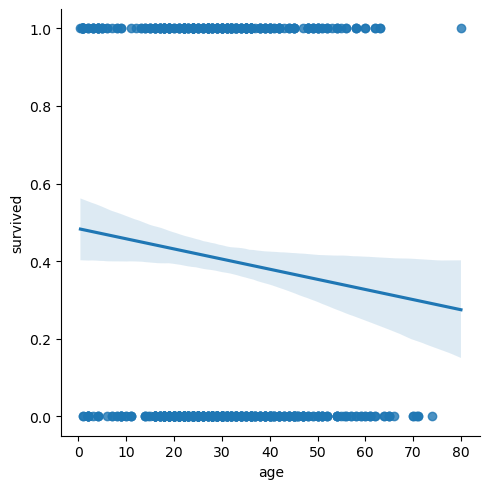

In [185]:
sns.lmplot(titanic_df,x='age',y='survived')
# top: People survived and their corresponding age
# bottopm : people not survived and corresponding age

**with x_bins we clean the figure more and instead of having every datapoint in figure**

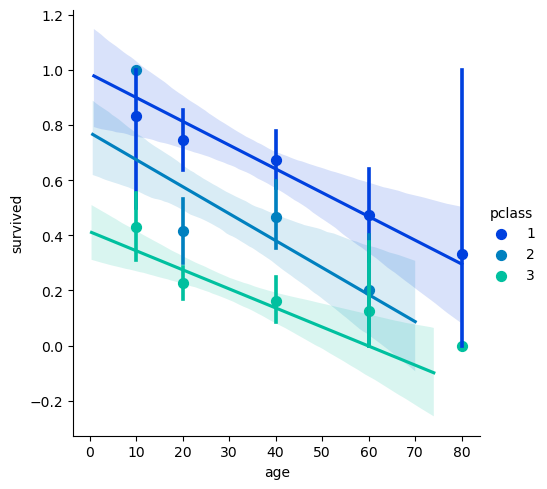

In [189]:
# grab ages that are closest and bin them by generation and get std on them
generations = [10,20,40,60,80]

sns.lmplot(titanic_df,x='age',y='survived',hue='pclass',palette='winter',x_bins=generations)

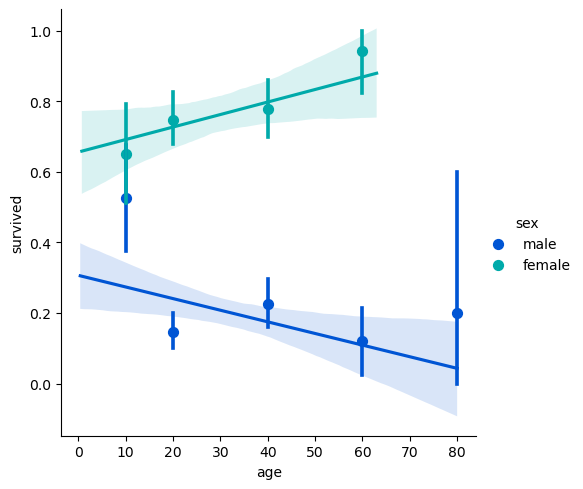

In [190]:
sns.lmplot(titanic_df,x='age',y='survived',hue='sex',palette='winter',x_bins=generations)
# older female: more chance for surving than older man

1)Did the deck have an effect on the passengers survival rate?Did this answer match up with your intuition?

2)Did having a family member increase the odds of surviving crash?

**me**

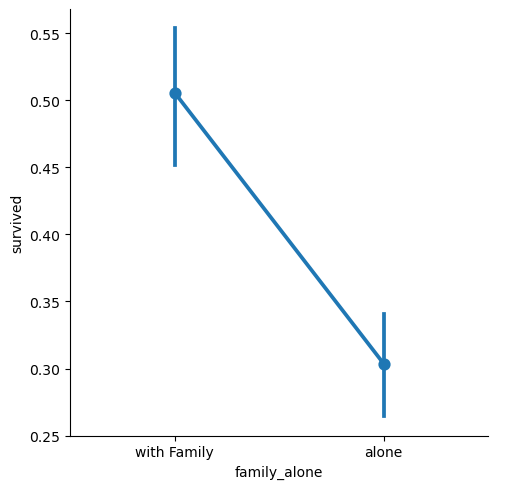

In [193]:
sns.catplot(titanic_df,x='family_alone',y='survived',kind='point')

In [194]:
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person,family_alone,alone,survivor
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male,with Family,With Family,no
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female,with Family,With Family,yes
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female,alone,Alone,yes
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female,with Family,With Family,yes
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male,alone,Alone,no


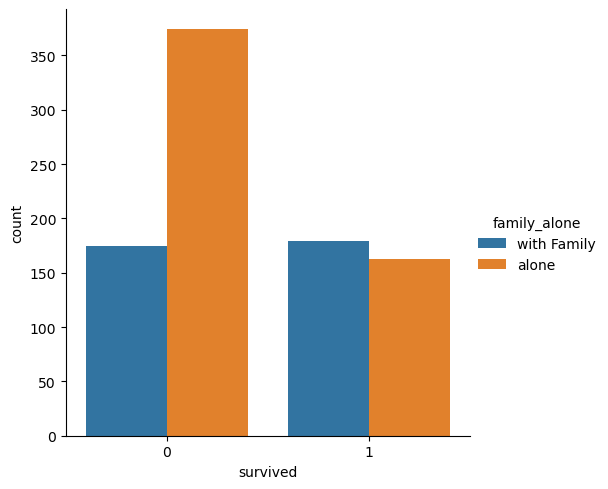

In [195]:
sns.catplot(titanic_df,x='survived',kind='count',hue='family_alone')

In [197]:
levels=[]
titanic_df['cabin']
for i in titanic_df['cabin']:
    levels.append(str(i)[0])
titanic_df['levels'] = levels
titanic_df.head()

,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,person,family_alone,alone,survivor,levels
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,male,with Family,With Family,no,n
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,female,with Family,With Family,yes,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,female,alone,Alone,yes,n
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,female,with Family,With Family,yes,C
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,male,alone,Alone,no,n


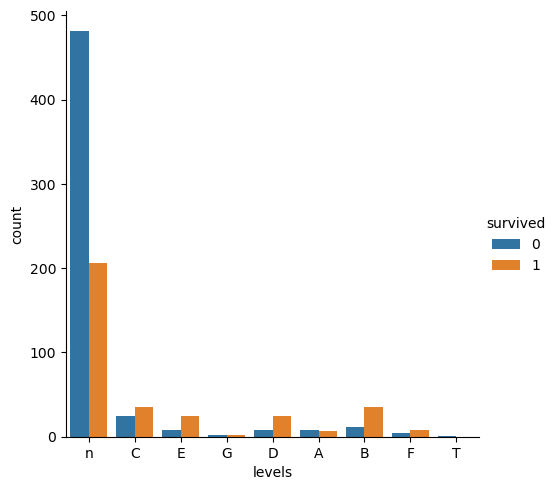

In [198]:
sns.catplot(data=titanic_df,x='levels',kind='count',hue='survived')